In [3]:
# imports

# from google.colab import drive
import os
import cv2
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import tensorflow as tf
import keras
from pathlib import Path
# print("GPU:", tf.config.list_physical_devices("GPU"))


ModuleNotFoundError: No module named 'cv2'

In [1]:
########### EDA :

# testing to get an image and display it :

"""

for kaggle : 

dataset_path = "/kaggle/input/datasets/mohamedaminerahmani/neurrron/Data"
images_no_tumor_path = "/kaggle/input/datasets/mohamedaminerahmani/neurrron/Data/notumor"
first_image_path = os.path.join(images_no_tumor_path, 'Te-no_0011.jpg')


"""
dataset_path = "../data/Data"
images_no_tumor_path = os.path.join(dataset_path, "notumor")
first_image_path = os.path.join(images_no_tumor_path, 'Te-no_0011.jpg')


image = cv2.imread(first_image_path)

image = cv2.cvtColor(image , cv2.COLOR_BGR2RGB)
plt.imshow(image)
plt.axis("off")
plt.show()






NameError: name 'os' is not defined

In [3]:
# data folders :

data_folders = os.listdir(dataset_path)
data_folders

['pituitary', 'notumor', 'meningioma', 'glioma']

In [4]:
# get all extensions of the images in each directory , and also count them :

folder_extensions = {}

for folder in data_folders :

    images_paths = os.listdir(os.path.join(dataset_path, folder))


    for image_path in images_paths :

        extension = image_path.split(".")[1]

        if folder not in folder_extensions :
            folder_extensions[folder]  = []

        if extension not in folder_extensions[folder] :
            folder_extensions[folder].append(extension)






folder_extensions

{'pituitary': ['jpg'],
 'notumor': ['jpg'],
 'meningioma': ['jpg'],
 'glioma': ['jpg']}

In [5]:
# showing each folder with all its extensions :

for folder , v in folder_extensions.items() :
    print( f"[+] {folder}  => {v}")

[+] pituitary  => ['jpg']
[+] notumor  => ['jpg']
[+] meningioma  => ['jpg']
[+] glioma  => ['jpg']


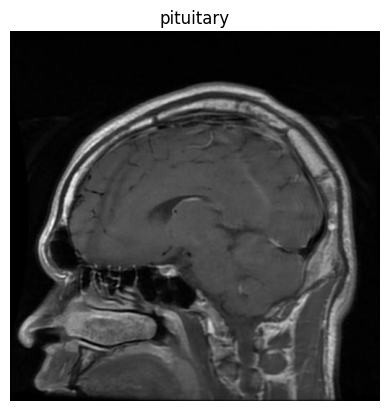

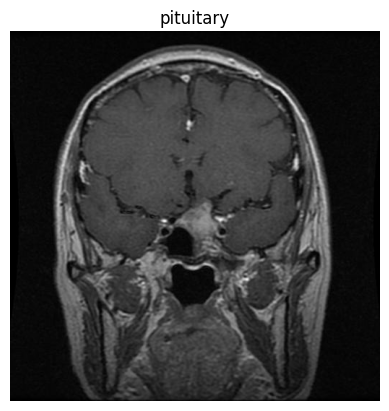

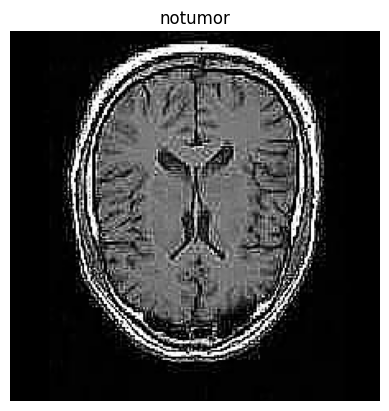

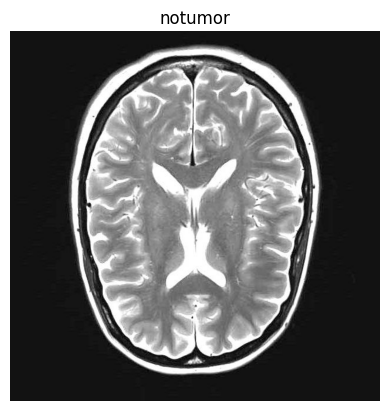

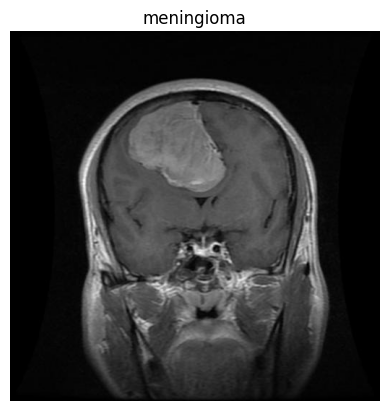

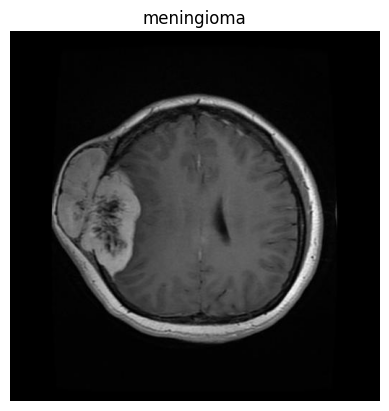

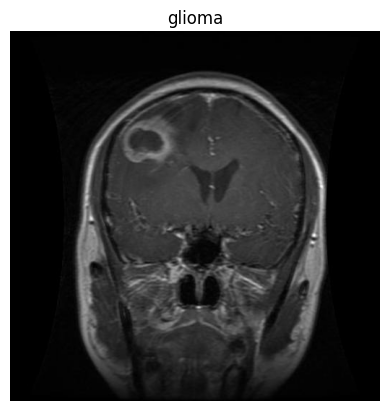

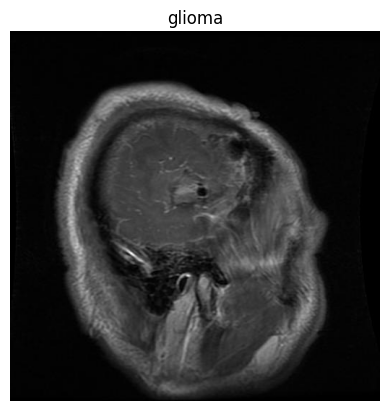

In [6]:
# displaying 2 images in each folder :

for folder in os.listdir(dataset_path):

  two_images_paths = os.listdir(os.path.join(dataset_path , folder))[:2]

  for image_path in two_images_paths :

      image = cv2.imread(os.path.join(dataset_path , folder, image_path))

      image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

      plt.imshow(image)
      plt.title(folder)
      plt.axis("off")
      plt.show()



In [7]:
# check image demensions in to see if we have same demnsions in all images :
result = []
for folder in data_folders:

    for image_path in os.listdir(os.path.join(dataset_path, folder)):

        image = cv2.imread(os.path.join(dataset_path, folder , image_path))

        img_demensions = image.shape

        if img_demensions not in result :

            result.append(img_demensions)




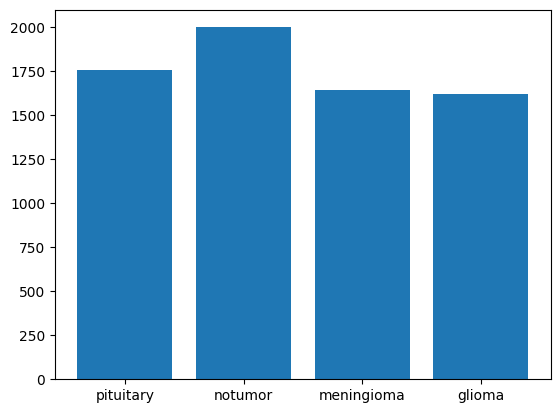

In [8]:
# visualize the distribution :



categories = data_folders


values  = []


for folder in data_folders :

  images_count= len(os.listdir(os.path.join(dataset_path, folder)))

  values.append(images_count)



plt.bar(categories , values)
plt.show()

In [9]:
### Preprocessing :

# image with their labels :



def load_images(dataset_path , data_folders) :

   images = []

   labels = []

   for folder in data_folders :

       for image_path in os.listdir(os.path.join(dataset_path, folder)) :


           image  = cv2.imread(os.path.join(dataset_path, folder, image_path))

           image = cv2.cvtColor(image , cv2.COLOR_BGR2RGB)



           images.append(image)
           labels.append(folder)


   return images , labels

images , labels = load_images(dataset_path, data_folders)

In [10]:
# resizing the all the images :

for index , image in enumerate(images):

  images[index] = cv2.resize(image , (255 , 255), interpolation=cv2.INTER_LINEAR)





In [11]:
  # check the size of the images now :
result_sizes = []
for image in images :
    if image.shape not in result_sizes :
          result_sizes.append(image.shape)

result_sizes    # all images now have same width and high .

[(255, 255, 3)]

In [12]:
# converting the images to ndarray :

images = np.array(images)
labels = np.array(labels)

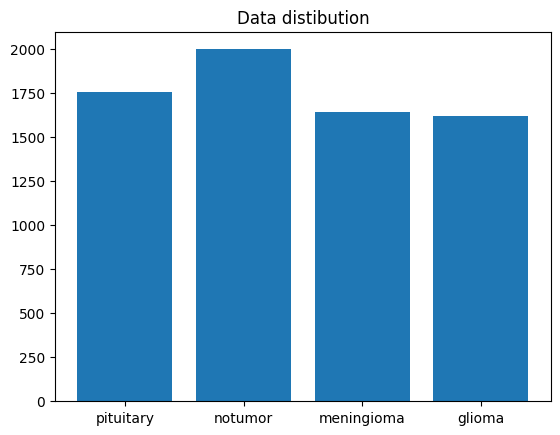

In [13]:
# displaying distribution of classes :
values = []
for folder in data_folders :

  folder_images_paths= os.listdir(os.path.join(dataset_path, folder))
  values.append(len(folder_images_paths))






plt.bar(data_folders , values)
plt.title("Data distibution")
plt.show()




In [14]:
# labels encoding :
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()
labels_encoded = label_encoder.fit_transform(labels)
np.unique(labels_encoded)


array([0, 1, 2, 3])

In [15]:
# i will apply class weight so the class that has fewer images will get higher values as a weight  and i w.
from sklearn.utils.class_weight import compute_class_weight
classes = labels_encoded


weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=labels_encoded
)



classes_weights = dict(zip(classes, weights))
classes_weights

classes_weights = {
    int(k) : float(v)
    for k , v in classes_weights.items()
}

classes_weights

{3: 0.9992885600455321,
 2: 0.877875,
 1: 1.067325227963526,
 0: 1.0831276989512646}

In [16]:
# normalize images  :

normalized_images = images.astype("float32") / 255.0

normalized_images[0]

array([[[0.        , 0.        , 0.        ],
        [0.        , 0.        , 0.        ],
        [0.        , 0.        , 0.        ],
        ...,
        [0.        , 0.        , 0.        ],
        [0.        , 0.        , 0.        ],
        [0.        , 0.        , 0.        ]],

       [[0.        , 0.        , 0.        ],
        [0.        , 0.        , 0.        ],
        [0.        , 0.        , 0.        ],
        ...,
        [0.        , 0.        , 0.        ],
        [0.        , 0.        , 0.        ],
        [0.        , 0.        , 0.        ]],

       [[0.        , 0.        , 0.        ],
        [0.        , 0.        , 0.        ],
        [0.        , 0.        , 0.        ],
        ...,
        [0.00392157, 0.00392157, 0.00392157],
        [0.00392157, 0.00392157, 0.00392157],
        [0.00392157, 0.00392157, 0.00392157]],

       ...,

       [[0.        , 0.        , 0.        ],
        [0.        , 0.        , 0.        ],
        [0.        , 0

In [17]:
from sklearn.model_selection import train_test_split
from sklearn.utils import shuffle
# splitting the daat :
normalized_images , labels_encoded = shuffle(normalized_images , labels_encoded , random_state=42)

x_train , x_test , y_train , y_test  = train_test_split(
    normalized_images ,
    labels_encoded,
    random_state=42,
    test_size=0.20,
    stratify=labels_encoded
)


x_train , x_val_train , y_train , y_val_train  = train_test_split(
    x_train ,
    y_train,
    random_state=42,
    test_size=0.10,
    stratify=y_train
)

In [18]:
# training :
# (255 , 255)   height and width . 

import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.utils import to_categorical




train_labels = to_categorical(y_train, 4)
test_labels = to_categorical(y_test, 4)

y_val_labels = to_categorical(y_val_train, 4)

model = models.Sequential([
    layers.Conv2D(32 , (3,3), activation="relu", input_shape=(255 , 255 , 3)), 
    layers.MaxPooling2D(pool_size=(2,2)), 
    layers.Flatten(),
    layers.Dense(64 , activation='relu'), 
    layers.Dense(4, activation="softmax")
])





model.compile(
    optimizer="adam", 
    loss="categorical_crossentropy",
    metrics=["accuracy"]
    )



history = model.fit(x_train , train_labels  , epochs=10, validation_data=(x_val_train, y_val_labels) )



validation_data = (x_test , y_test)


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
I0000 00:00:1792170871.558985      50 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1792170871.562719      50 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Epoch 1/10
  5/158 ━━━━━━━━━━━━━━━━━━━━ 5s 37ms/step - accuracy: 0.1575 - loss: 18.6685

I0000 00:00:1792170889.015165     152 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


158/158 ━━━━━━━━━━━━━━━━━━━━ 15s 60ms/step - accuracy: 0.7002 - loss: 1.6081 - val_accuracy: 0.8968 - val_loss: 0.3307
Epoch 2/10
158/158 ━━━━━━━━━━━━━━━━━━━━ 6s 40ms/step - accuracy: 0.9280 - loss: 0.2120 - val_accuracy: 0.9217 - val_loss: 0.2101
Epoch 3/10
158/158 ━━━━━━━━━━━━━━━━━━━━ 6s 41ms/step - accuracy: 0.9778 - loss: 0.0736 - val_accuracy: 0.9270 - val_loss: 0.2333
Epoch 4/10
158/158 ━━━━━━━━━━━━━━━━━━━━ 6s 40ms/step - accuracy: 0.9941 - loss: 0.0306 - val_accuracy: 0.9431 - val_loss: 0.1869
Epoch 5/10
158/158 ━━━━━━━━━━━━━━━━━━━━ 6s 41ms/step - accuracy: 0.9992 - loss: 0.0113 - val_accuracy: 0.9128 - val_loss: 0.2377
Epoch 6/10
158/158 ━━━━━━━━━━━━━━━━━━━━ 6s 40ms/step - accuracy: 0.9998 - loss: 0.0061 - val_accuracy: 0.9306 - val_loss: 0.2100
Epoch 7/10
158/158 ━━━━━━━━━━━━━━━━━━━━ 6s 40ms/step - accuracy: 1.0000 - loss: 0.0023 - val_accuracy: 0.9288 - val_loss: 0.2207
Epoch 8/10
158/158 ━━━━━━━━━━━━━━━━━━━━ 6s 40ms/step - accuracy: 1.0000 - loss: 0.0013 - val_accuracy: 0.93

In [19]:
# model evaluation : 

test_loss , test_acc = model.evaluate(x_test , test_labels) 

print(f" test accuracy : {test_acc * 100:.2f}")

44/44 ━━━━━━━━━━━━━━━━━━━━ 2s 48ms/step - accuracy: 0.9317 - loss: 0.3123
 test accuracy : 93.17


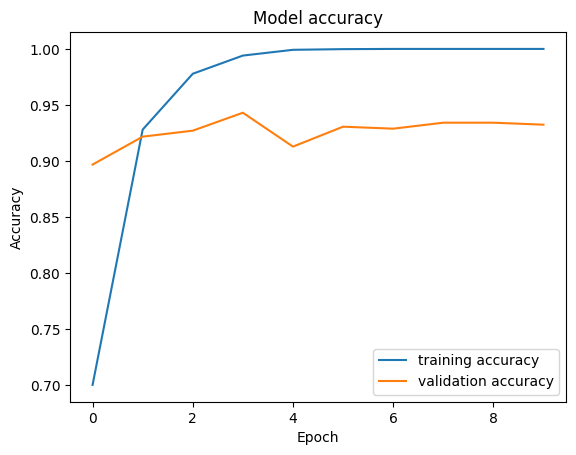

In [20]:
# accuracy with epochs
plt.plot(history.history["accuracy"], label="training accuracy")
plt.plot(history.history["val_accuracy"], label="validation accuracy")
plt.title("Model accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

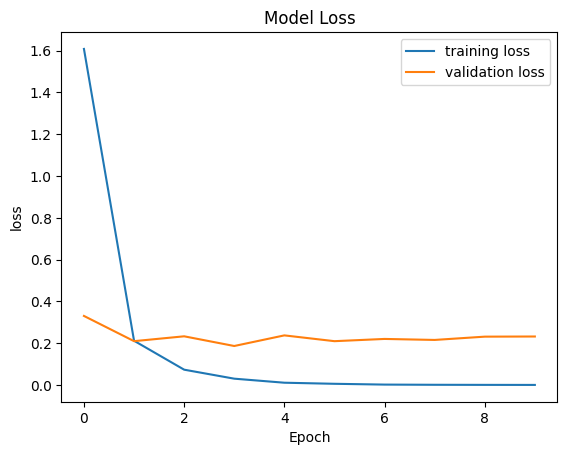

In [21]:
plt.plot(history.history["loss"], label="training loss")
plt.plot(history.history["val_loss"], label="validation loss")
plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("loss")
plt.legend()

plt.show()